In [7]:
%matplotlib inline
import sys
import h5py
import numpy as np
import torch
from torch.utils.data import ConcatDataset, DataLoader
import matplotlib.pyplot as plt
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
from matplotlib.ticker import LogLocator
from sklearn.metrics import roc_curve, auc

sys.path.append("/data/condor_shared/users/nmanic/RNO_machine_learning/RNO_classifier/classifier_consistency/train_eval")

from train_benchmark import ARCH_REGISTRY, WaveformDataset
from evaluate_comparison import get_scores, threshold_at_fpr

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["cmr10", "Computer Modern Roman", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "axes.unicode_minus": False,
})

ckpt_path = "/data/i3store/users/nmanic/classifier_consistency/ARZ2020/benchmark/runs/exp01/best_model.pt"

# Variables for choosing plotting data
signal_path = "/data/i3store/users/nmanic/classifier_consistency/ARZ2020/benchmark/nu/nu_extracted.hdf5"
noise_path = "/data/i3store/users/nmanic/classifier_consistency/ARZ2020/benchmark/noise/noise_extracted.hdf5"
target_fpr = 1e-5
# Set compare to True if signal & noise files aren't what the model was trained on
compare = False
batch_size = 512

device = (torch.device("cuda") if torch.cuda.is_available() else
              torch.device("mps")  if torch.backends.mps.is_available() else
              torch.device("cpu"))

ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
cfg  = ckpt.get("config", {})

model = ARCH_REGISTRY[cfg.get("arch", "baseline")](n_channels=4).to(device)
model.load_state_dict(ckpt["model_state"])

if "sig_val_idx" not in ckpt or "noi_val_idx" not in ckpt:
        sys.exit(
            "ERROR: checkpoint does not contain val indices.\n"
            "Re-run step2_train.py to produce a new checkpoint, then evaluate again."
        )
sig_val_idx = ckpt["sig_val_idx"]
noi_val_idx = ckpt["noi_val_idx"]

if compare:
    with h5py.File(signal_path, "r") as f:
        sig_val_idx = np.arange(f["waveforms"].shape[0])
    with h5py.File(noise_path,  "r") as f:
        noi_val_idx = np.arange(f["waveforms"].shape[0])
    print(f"Comparison mode: using all {len(sig_val_idx)} signal "
        f"and {len(noi_val_idx)} noise events")

crop = cfg.get("crop_samples", None)
val_ds = ConcatDataset([
    WaveformDataset(signal_path, sig_val_idx, crop),
    WaveformDataset(noise_path,  noi_val_idx, crop),
])
loader = DataLoader(val_ds, batch_size=batch_size,
                    shuffle=False, num_workers=4, persistent_workers=True,
                    pin_memory=(device.type == "cuda"))

# ── inference ─────────────────────────────────────────────────────────────
scores, val_labels = get_scores(model, loader, device)

# Gather SNR for signal val events (from HDF5 directly)
with h5py.File(signal_path, "r") as f:
    sig_snr_all = f["snr"][:]          # (N_sig, 4)
    trigger_scores_all = f["triggered"][:] if "triggered" in f else None # (N_sig,)

sig_snr_val = sig_snr_all[sig_val_idx]
if trigger_scores_all is not None:
    print('Found triggered dataset, will plot this as well for comparison')
    trigger_scores_val = trigger_scores_all[sig_val_idx]
    noise_trigger_val = np.zeros(len(noi_val_idx), dtype=np.int8)
    trigger_scores_val = np.concatenate([trigger_scores_val, noise_trigger_val], axis=0)
else:
    print('Did not find triggered dataset')
    trigger_scores_val = None
    
# Pad noise SNR with NaN so arrays align with val_labels
noise_snr_val = np.full((len(noi_val_idx), 4), float("nan"), dtype=np.float32)
snr_val = np.concatenate([sig_snr_val, noise_snr_val], axis=0)
# nanmax gives NaN for all-NaN rows (noise events); replace with 0 for plotting
snr_per_event = np.where(
    np.all(np.isnan(snr_val), axis=1),
    0.0,
    np.nanmax(snr_val, axis=1),
)

# ── ROC + threshold ───────────────────────────────────────────────────────
fpr_arr, tpr_arr, thresholds = roc_curve(val_labels, scores, pos_label=1)
roc_auc = auc(fpr_arr, tpr_arr)
threshold, op_fpr, op_tpr = threshold_at_fpr(
    fpr_arr, tpr_arr, thresholds, target_fpr)

Found triggered dataset, will plot this as well for comparison


/tmp/ipykernel_2351238/3797599232.py:95: RuntimeWarning: All-NaN slice encountered
  np.nanmax(snr_val, axis=1),


/tmp/ipykernel_2351238/3058196444.py:10: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  fig,ax=plt.subplots(figsize=(7, 4))


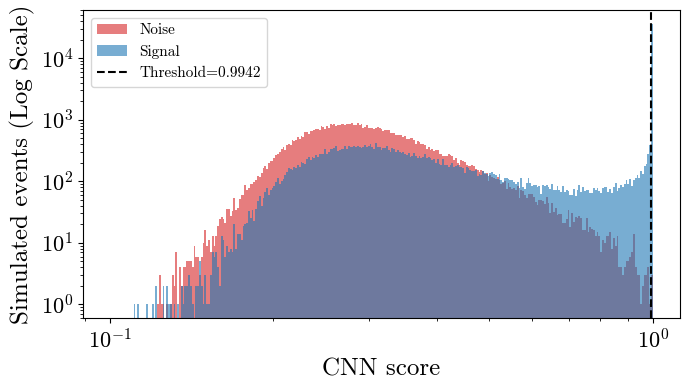

smallest achievable nonzero FPR: 1.4965131244201011e-05
A=222.126, lambda=8.205
Cut at 1.046691


/tmp/ipykernel_2351238/3058196444.py:62: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  fig, ax = plt.subplots(figsize=(7, 4))


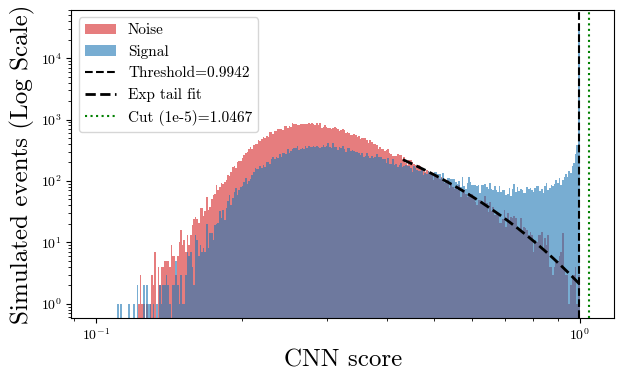

In [11]:
from scipy.optimize import curve_fit

n_bins = 300
labelsize=18

score_floor=.1

bins=np.logspace(np.log10(score_floor),np.log10(scores.max()),n_bins)

fig,ax=plt.subplots(figsize=(7, 4))
ax.hist(scores[val_labels == 0], bins=bins, range=(0, 1),
        alpha=0.6, color="tab:red",  label="Noise")
ax.hist(scores[val_labels == 1], bins=bins, range=(0, 1),
        alpha=0.6, color="tab:blue", label="Signal")
ax.axvline(threshold, ls="--", color="black", label=f"Threshold={threshold:.4f}")
ax.set_xlabel("CNN score", fontsize=labelsize) 
ax.set_ylabel("Simulated events (Log Scale)", fontsize=labelsize)
ax.legend(loc="upper left",fontsize=11)
ax.set_xscale("log")
ax.set_yscale("log")
#ax.set_xlim(.95, 1.05)
ax.tick_params(axis='both', which='major', labelsize=16)

#ax.grid(True, alpha=0.5)

fig.tight_layout()
plt.show()
nonzero_fpr = fpr_arr[fpr_arr > 0]
print("smallest achievable nonzero FPR:", nonzero_fpr.min() if len(nonzero_fpr) else "none (all zero)")

noise_scores=scores[val_labels==0]
n_total=len(scores)
t0=np.quantile(noise_scores, .90)

counts,edges=np.histogram(noise_scores,bins=bins)
centers=np.sqrt(edges[:-1]*edges[1:])
widths=edges[1:]-edges[:-1]

mask=(centers>t0) & (counts>0)
x_fit=centers[mask]
y_fit=counts[mask]

def exp_model(x, A, lam):
    return A * np.exp(-lam * (x - t0))

popt, pcov = curve_fit(
    exp_model, x_fit, y_fit,
    p0=[y_fit[0], 50],    
    sigma=np.sqrt(y_fit),                   
    absolute_sigma=True,
    maxfev=10000
)
A, lam = popt
print(f"A={A:.3f}, lambda={lam:.3f}")

target_count=1e-5*n_total
cut=t0-np.log(target_count/A)/lam
print(f"Cut at {cut:.6f}")

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(scores[val_labels == 0], bins=bins, range=(0, 1),
        alpha=0.6, color="tab:red",  label="Noise")
ax.hist(scores[val_labels == 1], bins=bins, range=(0, 1),
        alpha=0.6, color="tab:blue", label="Signal")
ax.axvline(threshold, ls="--", color="black", label=f"Threshold={threshold:.4f}")
ax.set_xlabel("CNN score", fontsize=labelsize) 
ax.set_ylabel("Simulated events (Log Scale)", fontsize=labelsize)

x_plot = np.logspace(np.log10(t0), np.log10(bins[-1]), 200)
ax.plot(x_plot, exp_model(x_plot, *popt), color="black", lw=2, ls="--", label="Exp tail fit")
ax.axvline(cut, ls=":", color="green", label=f"Cut (1e-5)={cut:.4f}")

ax.set_xscale("log")
ax.set_yscale("log")
ax.legend(loc="upper left", fontsize=11)
plt.show()


/tmp/ipykernel_2351238/1731312508.py:1: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  fig,ax=plt.subplots(figsize=(6,5))
/tmp/ipykernel_2351238/1731312508.py:10: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  ax2=ax.twinx()


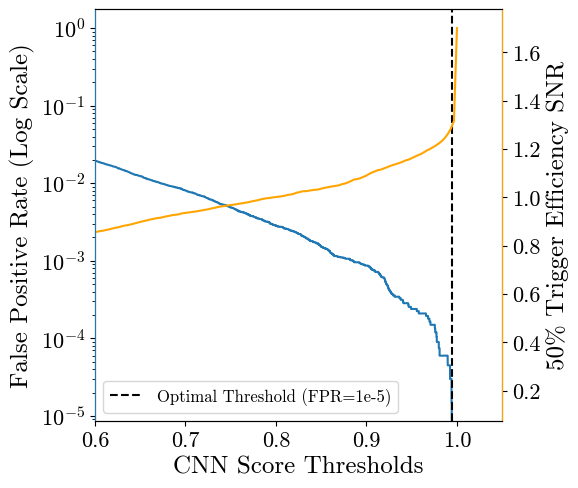

In [9]:
fig,ax=plt.subplots(figsize=(6,5))
ax.plot(thresholds,fpr_arr)
ax.set_yscale("log")
ax.axvline(threshold, ls="--", color="black", label="Optimal Threshold (FPR=1e-5)")
ax.set_ylabel("False Positive Rate (Log Scale)", fontsize=labelsize)
ax.set_xlabel("CNN Score Thresholds", fontsize=labelsize)
ax.legend(loc='lower left', fontsize=12)
ax.tick_params(axis='both', which='major', labelsize=16)

ax2=ax.twinx()
ax2.set_ylabel("50% Trigger Efficiency SNR", fontsize=labelsize)
ax2.tick_params(axis='both', which='major', labelsize=16)

n_bins = 20
snr_max = 6.0

sig_mask = val_labels == 1
sig_scores_all = scores[sig_mask]
sig_snr = snr_per_event[sig_mask]

bin_edges = np.linspace(0, snr_max, n_bins + 1)
all_edges = np.append(bin_edges, np.inf)
centres   = 0.5 * (bin_edges[:-1] + bin_edges[1:])
centres   = np.append(centres, snr_max + 0.5 * snr_max / n_bins)  # overflow centre

#subsample of threshold values since not all are needed for a smooth curve
plot_thresholds = np.linspace(0, 1, 300)
thresh_effs = []
for thresh in plot_thresholds:
    effs, counts = [], []
    for lo, hi in zip(all_edges[:-1], all_edges[1:]):
        mask  = (sig_snr >= lo) & (sig_snr < hi)
        n_tot = mask.sum()
        if n_tot == 0:
            effs.append(np.nan); counts.append(0)
            continue
        n_pass = (sig_scores_all[mask] >= thresh).sum()
        effs.append(n_pass / n_tot)
        counts.append(n_tot)

    effs   = np.array(effs)
    counts = np.array(counts)
    valid  = counts > 0

    # need effs to actually span 0.5 and be increasing to interpolate meaningfully
    if not np.any(valid) or effs[valid].max() < 0.5 or effs[valid].min() > 0.5:
        thresh_effs.append(np.nan)
        continue

    # enforce monotonic xp for np.interp
    order = np.argsort(effs[valid])
    thresh_effs.append(np.interp(0.5, effs[valid][order], centres[valid][order]))

thresh_effs = np.array(thresh_effs)
ax2.plot(plot_thresholds, thresh_effs, color='orange')

lines1, labs1 = ax.get_legend_handles_labels()
lines2, labs2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labs1 + labs2, loc='lower left', fontsize=12)
ax.set_xlim(.6,1.05)
ax2.spines["left"].set_color("tab:blue")
ax2.spines["right"].set_color("orange")
fig.tight_layout()
plt.show()


/tmp/ipykernel_2351238/620235932.py:14: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  fig,ax=plt.subplots(figsize=(6, 5))
/tmp/ipykernel_2351238/620235932.py:19: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  cb = plt.colorbar(h[3], label=("Event count (Log Scale)"))


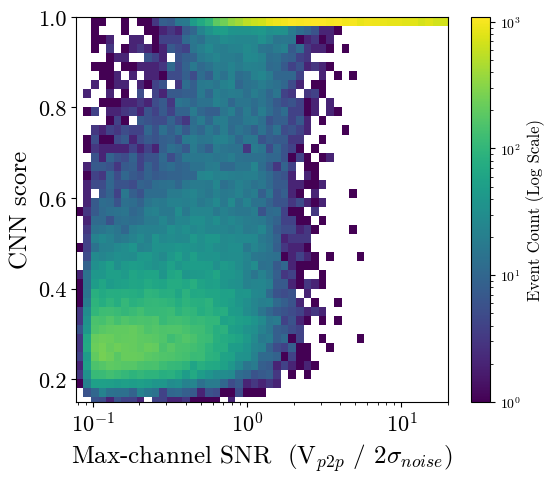

/tmp/ipykernel_2351238/620235932.py:29: UserWarning: cmr10 font should ideally be used with mathtext, set axes.formatter.use_mathtext to True
  fig,ax=plt.subplots(figsize=(6, 5))


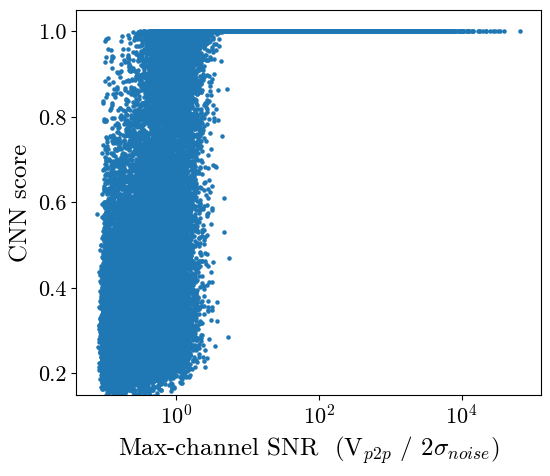

In [10]:
import matplotlib.colors as mcolors
n_sig = len(sig_val_idx)
sig_scores = scores[:n_sig]
sig_labels = val_labels[:n_sig]

with h5py.File(signal_path, "r") as f:
    sig_snr_all = f["snr"][:]          # (N_sig_total, 4)

sig_snr_val = sig_snr_all[sig_val_idx]  # (N_sig, 4)

# collapse per-channel SNR to one value per event — max across channels
snr = np.nanmax(sig_snr_val, axis=1)    # (N_sig,) — now matches sig_scores

fig,ax=plt.subplots(figsize=(6, 5))
h = ax.hist2d(snr, sig_scores,
               bins=[np.logspace(np.log10(snr.min()), np.log10(20), 50), 50],
               cmap='viridis',
               norm=mcolors.LogNorm())
cb = plt.colorbar(h[3], label=("Event count (Log Scale)"))
cb.set_label("Event Count (Log Scale)", fontsize=12)
ax.set_xscale('log')
ax.set_xlim(snr.min(), 20)
ax.set_xlabel(r"Max-channel SNR  (V$_{p2p}$ / 2$\sigma_{noise}$)", fontsize=labelsize)
ax.set_ylabel("CNN score", fontsize=labelsize)
ax.set_ylim(.15,1.0)
ax.tick_params(axis='both', which='major', labelsize=16)
plt.show()

fig,ax=plt.subplots(figsize=(6, 5))
h=ax.scatter(snr, sig_scores, s=5)
ax.set_xscale('log')
ax.set_xlabel(r"Max-channel SNR  (V$_{p2p}$ / 2$\sigma_{noise}$)", fontsize=labelsize)
ax.set_ylabel("CNN score", fontsize=labelsize)
ax.set_ylim(.15,)
ax.tick_params(axis='both', which='major', labelsize=16)
plt.show()